# Expliquer un détecteur d'intrusion — UNSW-NB15
**Projet 1 (Interprétabilité) — Module Machine Learning pour la cybersécurité**

Question centrale : le modèle apprend-il des *comportements d'attaque* ou des *artefacts de collecte* ?

**Plan** : 0. Setup · 1. Données & nettoyage · 2. Découpage · 3. Modèles (socle commun) · 4. Évaluation · 5. Trois mesures d'importance · 6. Cinq alertes expliquées · 7. Audit de plausibilité · 8. Ablation · 9. Stabilité · 10. Conclusion & limites

**Données** (non versionnées) : télécharger `UNSW_NB15_training-set.csv` et `UNSW_NB15_testing-set.csv` (UNSW Canberra / Kaggle), les placer dans `data/`.

## 0. Setup et reproductibilité

In [1]:
import warnings, time, platform, random
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, shap
from scipy.stats import spearmanr, randint, uniform
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, classification_report, precision_recall_curve,
                             average_precision_score, roc_auc_score, f1_score, PrecisionRecallDisplay)
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("python", platform.python_version(), "| sklearn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| shap", shap.__version__, "| pandas", pd.__version__)

python 3.12.10 | sklearn 1.9.1 | xgboost 3.4.1 | shap 0.54.1 | pandas 3.1.1


## 1. Données et nettoyage

In [2]:
DATA = "data/"
raw_tr = pd.read_csv(DATA + "UNSW_NB15_training-set.csv")
raw_te = pd.read_csv(DATA + "UNSW_NB15_testing-set.csv")
print(raw_tr.shape, raw_te.shape)
raw_tr.head()

(82332, 45) (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


**À décrire dans le rapport** : origine (UNSW Canberra, ACCS), nature des variables (durées, paquets, octets, états, protocole, service…), classes (`label` 0/1 et `attack_cat` : 9 familles), proportion d'attaques (voir cellule suivante).

In [3]:
for name, d in [("train officiel", raw_tr), ("test officiel", raw_te)]:
    print(name, "| part d'attaques :", round(d["label"].mean(), 3))
print(raw_tr["attack_cat"].value_counts())

train officiel | part d'attaques : 0.551
test officiel | part d'attaques : 0.681
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


In [4]:
def clean(df):
    df = df.copy()
    n0 = len(df)
    df = df.drop(columns=[c for c in ["id"] if c in df.columns])      # simple index, pas une variable
    df = df.replace([np.inf, -np.inf], np.nan)
    print("valeurs manquantes :", int(df.isna().sum().sum()))
    df = df.dropna()
    df = df.drop_duplicates()
    print(f"lignes : {n0} -> {len(df)} (doublons/NaN retirés : {n0-len(df)})")
    return df

tr = clean(raw_tr); te = clean(raw_te)

# doublons ENTRE train et test (fuite directe) : on les retire du test
feat_cols = [c for c in tr.columns if c not in ("label", "attack_cat")]
key = lambda d: d[feat_cols].astype(str).agg("|".join, axis=1)
dup_cross = key(te).isin(set(key(tr)))
print("doublons train/test :", int(dup_cross.sum()), f"({dup_cross.mean():.1%} du test)")
te = te[~dup_cross].reset_index(drop=True)
tr = tr.reset_index(drop=True)

valeurs manquantes : 0
lignes : 82332 -> 55945 (doublons/NaN retirés : 26387)
valeurs manquantes : 0
lignes : 175341 -> 107740 (doublons/NaN retirés : 67601)
doublons train/test : 1722 (1.6% du test)


**Justifier chaque choix** : suppression des doublons (sinon fuite train→test), `inf`/NaN retirés (peu nombreux, ou à imputer sur le train seul), `id` retiré (index).
**À citer** : au moins une analyse publiée sur les défauts de UNSW-NB15 (et/ou CIC-IDS2017) — référence : `[à compléter]`.

## 2. Découpage entraînement / validation / test
Cette version du jeu n'a pas d'horodatage : un découpage chronologique est impossible. On garde donc le découpage **officiel** (train/test) pour le test, et on sépare le train en **train / validation** (stratifié, graine fixée).
**Limite à discuter** : découpage non temporel, flux d'une même session éventuellement répartis des deux côtés.

In [5]:
y_all = tr["label"]
X_all = tr.drop(columns=["label", "attack_cat"])
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
X_test, y_test = te.drop(columns=["label", "attack_cat"]), te["label"]
attack_cat_test = te["attack_cat"].reset_index(drop=True)

cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]
print("catégorielles :", cat_cols, "| numériques :", len(num_cols))
print({k: (len(v), round(float(w.mean()), 3)) for k, (v, w) in
       {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}.items()})

catégorielles : ['proto', 'service', 'state'] | numériques : 39
{'train': (44756, 0.389), 'val': (11189, 0.389), 'test': (106018, 0.514)}


## 3. Modèles (socle commun) — tout est ajusté sur le train uniquement

In [6]:
# Encodage ordinal (ajusté sur le train) pour les arbres ; one-hot + standardisation pour la régression logistique
ord_enc = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)],
    remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
Xtr_t = ord_enc.fit_transform(X_train)
Xva_t = ord_enc.transform(X_val)
Xte_t = ord_enc.transform(X_test)
feature_names = Xtr_t.columns.tolist()

lr_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01), cat_cols),
    ("num", StandardScaler(), num_cols)])
baseline = Pipeline([("pre", lr_pre), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                                 random_state=SEED))])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

t0 = time.time(); baseline.fit(X_train, y_train); t_lr = time.time() - t0

rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, class_weight="balanced", random_state=SEED),
    {"n_estimators": randint(100, 300), "max_depth": [10, 20, None],
     "min_samples_leaf": randint(1, 10), "max_features": ["sqrt", 0.3]},
    n_iter=8, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1)
t0 = time.time(); rf_search.fit(Xtr_t, y_train); t_rf = time.time() - t0
rf = rf_search.best_estimator_

spw = float((y_train == 0).sum() / (y_train == 1).sum())
xgb_search = RandomizedSearchCV(
    XGBClassifier(tree_method="hist", n_jobs=-1, random_state=SEED, eval_metric="aucpr"),
    {"n_estimators": randint(150, 500), "max_depth": randint(3, 9),
     "learning_rate": uniform(0.03, 0.2), "subsample": uniform(0.7, 0.3),
     "colsample_bytree": uniform(0.6, 0.4), "scale_pos_weight": [1, spw]},
    n_iter=10, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1)
t0 = time.time(); xgb_search.fit(Xtr_t, y_train); t_xgb = time.time() - t0
xgb = xgb_search.best_estimator_
print("RF :", rf_search.best_params_); print("XGB:", xgb_search.best_params_)

RF : {'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 2, 'n_estimators': 291}
XGB: {'colsample_bytree': np.float64(0.6362425738131283), 'learning_rate': np.float64(0.15367720186661746), 'max_depth': 6, 'n_estimators': 204, 'scale_pos_weight': 1.573515036513139, 'subsample': np.float64(0.8777243706586126)}


## 4. Évaluation
On compare d'abord sur la **validation**. Le **test** n'est utilisé qu'une seule fois, pour les résultats finaux.

In [7]:
def report(name, y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    print(f"=== {name} ===")
    print(confusion_matrix(y_true, pred))
    print(classification_report(y_true, pred, digits=3, target_names=["normal", "attaque"]))
    return {"modèle": name, "PR-AUC": average_precision_score(y_true, proba),
            "ROC-AUC": roc_auc_score(y_true, proba), "F1 attaque": f1_score(y_true, pred)}

def infer_time(model, X, n=5):
    t0 = time.time()
    for _ in range(n): model.predict_proba(X)
    return (time.time() - t0) / n / len(X) * 1e6    # µs / flux

val_rows = [report("Baseline LR", y_val, baseline.predict_proba(X_val)[:, 1]),
            report("Random Forest", y_val, rf.predict_proba(Xva_t)[:, 1]),
            report("XGBoost", y_val, xgb.predict_proba(Xva_t)[:, 1])]
val_tab = pd.DataFrame(val_rows)
val_tab["train (s)"] = [t_lr, t_rf, t_xgb]
val_tab["inférence (µs/flux)"] = [infer_time(baseline, X_val), infer_time(rf, Xva_t), infer_time(xgb, Xva_t)]
val_tab.round(4)

=== Baseline LR ===
[[5834 1007]
 [ 428 3920]]
              precision    recall  f1-score   support

      normal      0.932     0.853     0.890      6841
     attaque      0.796     0.902     0.845      4348

    accuracy                          0.872     11189
   macro avg      0.864     0.877     0.868     11189
weighted avg      0.879     0.872     0.873     11189

=== Random Forest ===
[[6669  172]
 [ 184 4164]]
              precision    recall  f1-score   support

      normal      0.973     0.975     0.974      6841
     attaque      0.960     0.958     0.959      4348

    accuracy                          0.968     11189
   macro avg      0.967     0.966     0.967     11189
weighted avg      0.968     0.968     0.968     11189

=== XGBoost ===
[[6700  141]
 [ 160 4188]]
              precision    recall  f1-score   support

      normal      0.977     0.979     0.978      6841
     attaque      0.967     0.963     0.965      4348

    accuracy                          0.973

,modèle,PR-AUC,ROC-AUC,F1 attaque,train (s),inférence (µs/flux)
0,Baseline LR,0.9446,0.9589,0.8453,1.3211,2.1005
1,Random Forest,0.9924,0.9946,0.9590,66.6244,7.3773
2,XGBoost,0.9941,0.9958,0.9653,32.3185,1.3320


**Discussion à rédiger** (coût des erreurs) : un faux négatif = attaque non détectée (compromission, exfiltration) ; un faux positif = alerte inutile pour l'analyste (fatigue d'alerte, temps perdu). Argumenter le seuil de décision retenu et son lien avec la charge d'alertes. La PR-AUC se lit par rapport à la proportion d'attaques (référence d'un modèle aléatoire).

### Résultats finaux sur le test (une seule fois)

In [8]:
test_rows = [report("Baseline LR", y_test, baseline.predict_proba(X_test)[:, 1]),
             report("Random Forest", y_test, rf.predict_proba(Xte_t)[:, 1]),
             report("XGBoost", y_test, xgb.predict_proba(Xte_t)[:, 1])]
pd.DataFrame(test_rows).round(4)

=== Baseline LR ===
[[48160  3336]
 [12734 41788]]
              precision    recall  f1-score   support

      normal      0.791     0.935     0.857     51496
     attaque      0.926     0.766     0.839     54522

    accuracy                          0.848    106018
   macro avg      0.858     0.851     0.848    106018
weighted avg      0.860     0.848     0.848    106018

=== Random Forest ===
[[50477  1019]
 [13799 40723]]
              precision    recall  f1-score   support

      normal      0.785     0.980     0.872     51496
     attaque      0.976     0.747     0.846     54522

    accuracy                          0.860    106018
   macro avg      0.880     0.864     0.859    106018
weighted avg      0.883     0.860     0.859    106018

=== XGBoost ===
[[50409  1087]
 [13451 41071]]
              precision    recall  f1-score   support

      normal      0.789     0.979     0.874     51496
     attaque      0.974     0.753     0.850     54522

    accuracy                   

,modèle,PR-AUC,ROC-AUC,F1 attaque
0,Baseline LR,0.9562,0.9582,0.8387
1,Random Forest,0.9761,0.9754,0.8461
2,XGBoost,0.9755,0.9755,0.8496


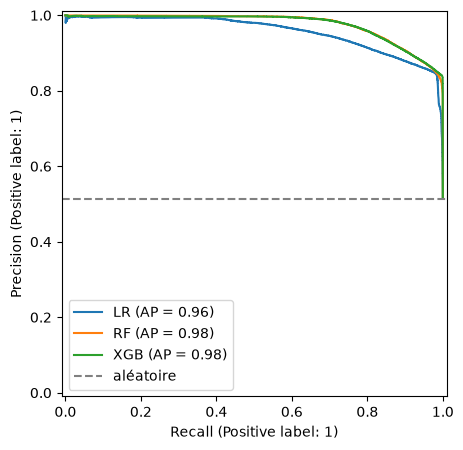

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [("LR", baseline.predict_proba(X_test)[:, 1]), ("RF", rf.predict_proba(Xte_t)[:, 1]),
                ("XGB", xgb.predict_proba(Xte_t)[:, 1])]:
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax)
ax.axhline(y_test.mean(), ls="--", c="gray", label="aléatoire"); ax.legend(); plt.show()

## 5. Trois mesures d'importance (modèle expliqué : Random Forest)
Importance interne (MDI) · importance par permutation sur le test (baisse de PR-AUC) · moyenne des |SHAP|.
Rappel des pièges : variables corrélées (importance répartie ou masquée), importances à ne pas lire comme des effets isolés.

In [10]:
imp_mdi = pd.Series(rf.feature_importances_, index=feature_names, name="MDI")

rng = np.random.RandomState(SEED)
idx_perm = rng.choice(len(Xte_t), size=min(10000, len(Xte_t)), replace=False)
perm = permutation_importance(rf, Xte_t.iloc[idx_perm], y_test.iloc[idx_perm],
                              scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
imp_perm = pd.Series(perm.importances_mean, index=feature_names, name="Permutation")

# SHAP : échantillon de 2000 flux au plus, tiré dans le test
idx_shap = rng.choice(len(Xte_t), size=min(2000, len(Xte_t)), replace=False)
Xs = Xte_t.iloc[idx_shap]
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)   # classe « attaque »
imp_shap = pd.Series(np.abs(sv).mean(axis=0), index=feature_names, name="|SHAP|")

imp = pd.concat([imp_mdi, imp_perm, imp_shap], axis=1)
ranks = imp.rank(ascending=False)
imp_tab = imp.join(ranks.add_suffix(" (rang)")).sort_values("|SHAP|", ascending=False)
imp_tab.head(15).round(4)

,MDI,Permutation,|SHAP|,MDI (rang),Permutation (rang),|SHAP| (rang)
sttl,0.1464,0.1939,0.1631,1.0,1.0,1.0
ct_state_ttl,0.1222,0.0463,0.0986,3.0,2.0,2.0
ct_dst_src_ltm,0.1432,0.0334,0.0807,2.0,4.0,3.0
ct_srv_dst,0.0645,0.0043,0.0368,4.0,9.0,4.0
dbytes,0.0283,0.0071,0.0274,10.0,5.0,5.0
sbytes,0.0521,0.0056,0.0211,5.0,7.0,6.0
dttl,0.0088,0.0340,0.0209,25.0,3.0,7.0
ct_dst_sport_ltm,0.0389,0.0045,0.0187,6.0,8.0,8.0
smean,0.0377,0.0036,0.0181,7.0,11.0,9.0
dload,0.0377,0.0029,0.0175,8.0,12.0,10.0


Corrélation de Spearman entre classements :
              MDI  Permutation  |SHAP|
MDI          1.00         0.64    0.92
Permutation  0.64         1.00    0.77
|SHAP|       0.92         0.77    1.00


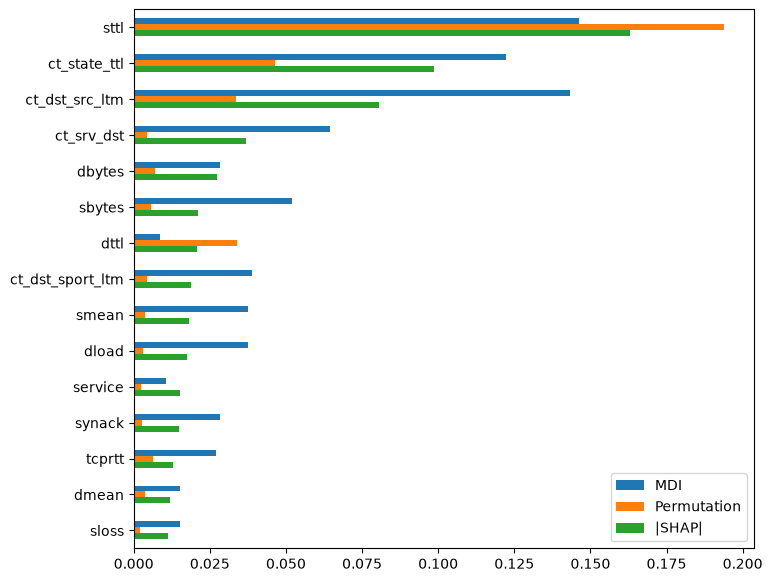

In [11]:
print("Corrélation de Spearman entre classements :")
print(ranks.corr(method="spearman").round(2))
imp_tab.head(15)[["MDI", "Permutation", "|SHAP|"]].plot.barh(figsize=(8, 7)); plt.gca().invert_yaxis(); plt.show()

**À discuter** : pourquoi les classements diffèrent (MDI biaisé vers variables à forte cardinalité, permutation et corrélations, SHAP et attribution partagée).

## 6. Cinq alertes expliquées (2 VP, 2 FP, 1 FN)
Pour chacune : valeurs clés, contributions SHAP, puis texte d'analyste.


##### VP | index test 97985 | proba=1.000 | famille=Reconnaissance


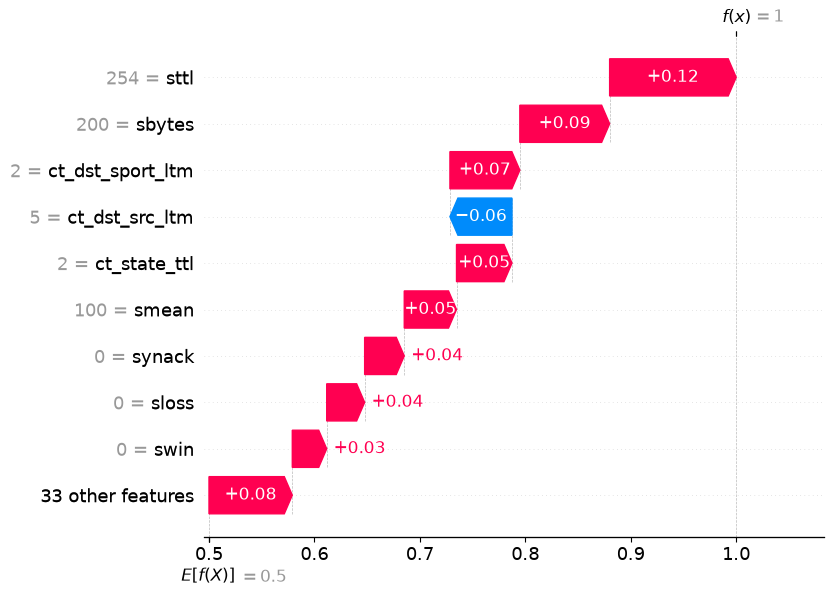


##### VP | index test 54806 | proba=0.882 | famille=Fuzzers


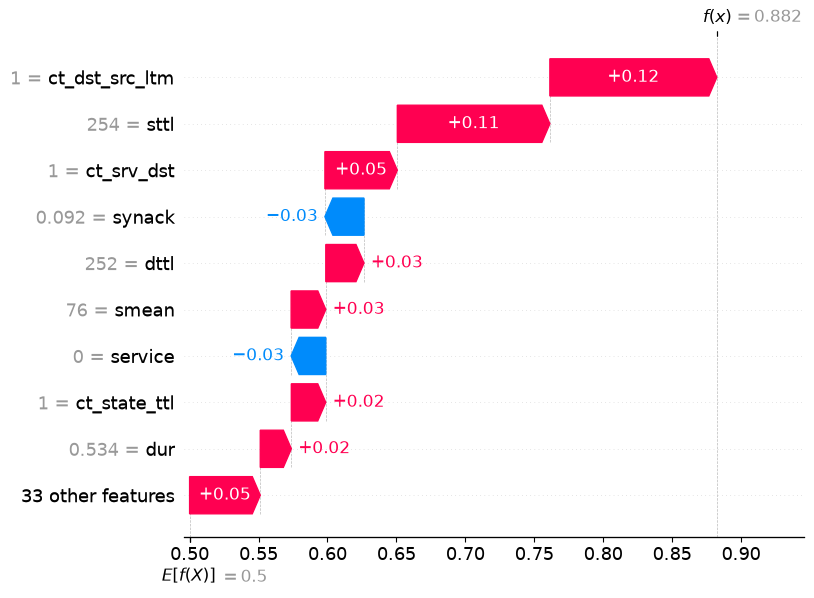


##### FP | index test 43581 | proba=0.942 | famille=Normal


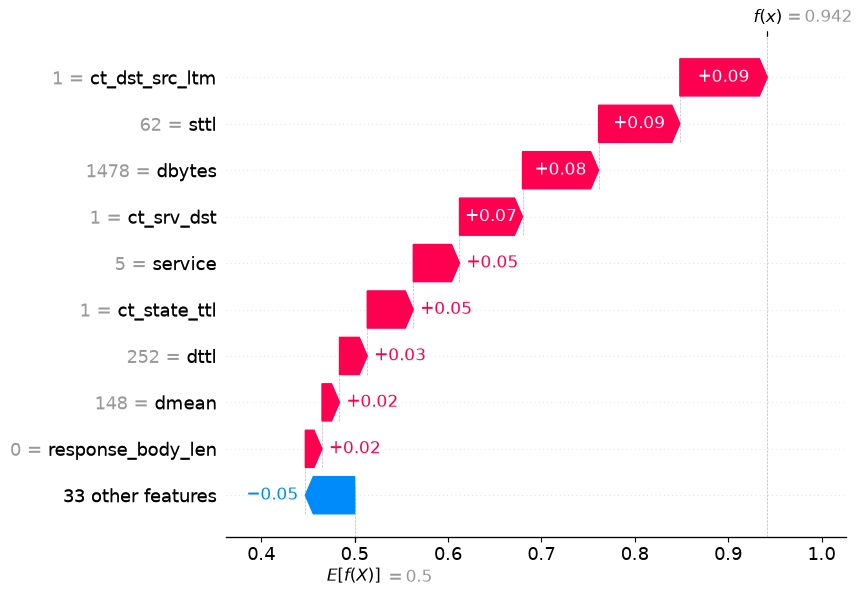


##### FP | index test 42971 | proba=0.694 | famille=Normal


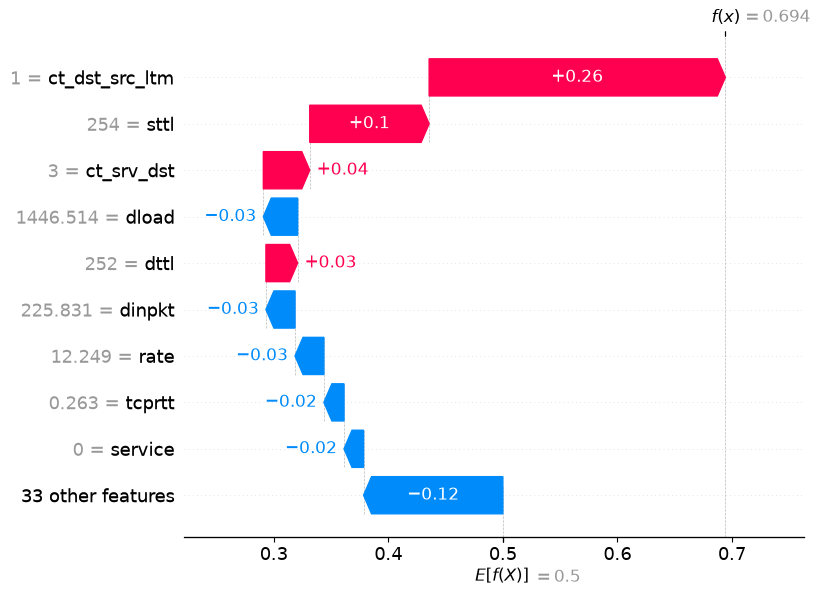


##### FN | index test 92468 | proba=0.267 | famille=Fuzzers


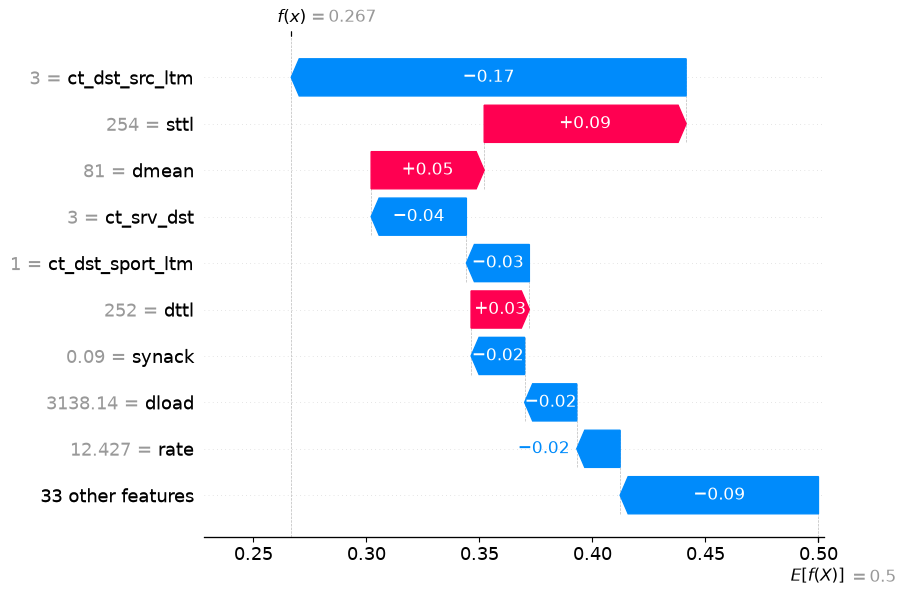

In [12]:
proba_te = rf.predict_proba(Xte_t)[:, 1]
pred_te = (proba_te >= 0.5).astype(int)
yt = y_test.values
pick = lambda mask, k: list(np.random.RandomState(SEED).choice(np.where(mask)[0], size=k, replace=False))
cases = {"VP": pick((pred_te == 1) & (yt == 1), 2),
         "FP": pick((pred_te == 1) & (yt == 0), 2),
         "FN": pick((pred_te == 0) & (yt == 1), 1)}
base = explainer.expected_value
base = base[1] if np.ndim(base) else base

for kind, ids in cases.items():
    for i in ids:
        s = explainer.shap_values(Xte_t.iloc[[i]])
        s = s[1][0] if isinstance(s, list) else (s[0, :, 1] if s.ndim == 3 else s[0])
        print(f"\n##### {kind} | index test {i} | proba={proba_te[i]:.3f} | famille={attack_cat_test[i]}")
        shap.plots.waterfall(shap.Explanation(values=s, base_values=base,
                             data=Xte_t.iloc[i].values, feature_names=feature_names), max_display=10)

**Texte d'analyste à rédiger pour chaque alerte** (modèle) :
> *Alerte n°X (VP/FP/FN).* Le flux [protocole/service/état] présente [variables dominantes + valeurs]. Le modèle le juge [malveillant/normal] surtout à cause de [contributions SHAP]. Du point de vue réseau, c'est [cohérent / suspect] car [...]. Action recommandée : [...].

## 7. Audit de plausibilité des 10 variables les plus importantes
Compléter le tableau (une ligne par variable) :

| Variable | Rôle réseau | Plausible comme signal d'attaque ? | Artefact possible ? | Verdict |
|---|---|---|---|---|
| … | … | … | … | … |

Variables à regarder de près : `sttl`, `dttl`, `ct_state_ttl`, `sbytes`/`dbytes`, `state`, `proto`, `service`, compteurs `ct_*`. Un TTL ou un compteur dépendant de la façon dont le trafic a été généré peut être un **artefact de collecte** plutôt qu'un comportement d'attaque.

In [16]:
top10 = imp_tab.head(10).index.tolist()
print(top10)

['sttl', 'ct_state_ttl', 'ct_dst_src_ltm', 'ct_srv_dst', 'dbytes', 'sbytes', 'dttl', 'ct_dst_sport_ltm', 'smean', 'dload']


## 8. Ablation : ré-entraînement sans les variables suspectes

In [18]:
SUSPECT = []   # <- à remplir après l'audit, ex. ["sttl", "ct_state_ttl"]
SUSPECT = ["sttl", "ct_state_ttl"]

keep = [c for c in feature_names if c not in SUSPECT]
rf_abl = RandomForestClassifier(**{k: v for k, v in rf.get_params().items()}).fit(Xtr_t[keep], y_train)
p_full = rf.predict_proba(Xte_t)[:, 1]
p_abl = rf_abl.predict_proba(Xte_t[keep])[:, 1]
pd.DataFrame([
    {"modèle": "complet", "PR-AUC": average_precision_score(y_test, p_full), "F1": f1_score(y_test, p_full >= .5)},
    {"modèle": f"sans {SUSPECT}", "PR-AUC": average_precision_score(y_test, p_abl), "F1": f1_score(y_test, p_abl >= .5)},
]).round(4)

,modèle,PR-AUC,F1
0,complet,0.9761,0.8461
1,"sans ['sttl', 'ct_state_ttl']",0.9731,0.8455


**Interprétation** : chute forte → le modèle initial s'appuyait sur ces variables (robuste ? artefact ?). Chute faible → robuste. Rapprocher du résultat de l'audit.

## 9. Stabilité des explications
On refait l'importance SHAP avec plusieurs graines (modèle + découpage) et on mesure la stabilité du top 10.

In [19]:
def shap_top(seed, k=10):
    Xa, _, ya, _ = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=seed)
    Xa_t = ord_enc.transform(Xa)
    m = RandomForestClassifier(**{**rf.get_params(), "random_state": seed}).fit(Xa_t, ya)
    ids = np.random.RandomState(seed).choice(len(Xte_t), size=min(1000, len(Xte_t)), replace=False)
    s = shap.TreeExplainer(m).shap_values(Xte_t.iloc[ids])
    s = s[1] if isinstance(s, list) else (s[..., 1] if s.ndim == 3 else s)
    return pd.Series(np.abs(s).mean(0), index=feature_names).sort_values(ascending=False).head(k).index.tolist()

tops = {sd: shap_top(sd) for sd in [1, 2, 3]}
sets = [set(v) for v in tops.values()]
jacc = np.mean([len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i+1:]])
print("Jaccard moyen du top-10 :", round(jacc, 2))
pd.DataFrame(tops)

Jaccard moyen du top-10 : 1.0


,1,2,3
0,sttl,sttl,sttl
1,ct_state_ttl,ct_state_ttl,ct_state_ttl
2,ct_dst_src_ltm,ct_dst_src_ltm,ct_dst_src_ltm
3,ct_srv_dst,ct_srv_dst,ct_srv_dst
4,dttl,dbytes,dttl
5,dbytes,dttl,dbytes
6,dload,smean,smean
7,ct_dst_sport_ltm,sbytes,sbytes
8,sbytes,dload,dload
9,smean,ct_dst_sport_ltm,ct_dst_sport_ltm


## 10. Conclusion et limites
**Réponse à la question centrale** : [le modèle apprend-il des comportements d'attaque ou des particularités du jeu ? argumenter avec : audit, ablation, stabilité].

**Limites** : découpage non temporel ; un seul jeu ; SHAP sur 2 000 flux ; corrélations entre variables ; [à compléter].

**Extension (optionnel)** : comparer les explications RF vs XGBoost ; traiter séparément les familles d'attaques.